# TIME-DEPENDENT SCHRODINGER EQUATION FOR GAUSSIAN WAVEPACKET IN A BOX

In [1]:
from matplotlib import pyplot as plt
import numpy as np
import scipy
from matplotlib.animation import PillowWriter

In [165]:
#parameters and constants

hbar = 1.
m = 1.
k = np.sqrt(2.) #kinetic energy is equal to 1
L = 1. #box is from -L to L

#gaussian parameters

mu = 0.5
sigma = 0.05

dx  = 0.001 

x = np.linspace(0 + dx, L - dx, int((L - 2*dx)/dx + 1))

dt = dx/(np.sqrt(2.)) #when m=1 and k = sqrt(2)
t = np.linspace(0, 0.5, int(0.5/dt + 1))


psi = np.zeros((len(t),len(x)), dtype = np.complex128)

#wavefunction

psi[0,:]= (1/np.sqrt(sigma*np.sqrt(2*np.pi)))*np.exp(-((x-mu)**2.0)/(2*sigma)**2.0)*np.exp(1j*k*x)

## Check Initial Data

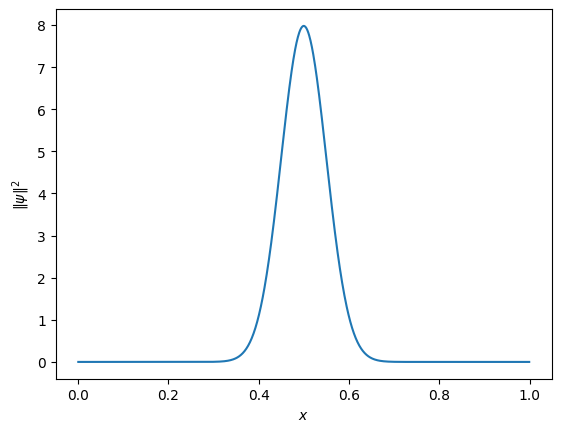

In [166]:


plt.plot(x, np.abs(psi[0,:])**2)
plt.xlabel(r'$x$')
plt.ylabel(r'$\|\psi\|^2$')
plt.show()

In [167]:
#check normalization using gaussian-legendre quadrature

   
nodes, weights = scipy.special.roots_legendre(100)

nodesp = 0.5*(L - 0)*nodes + 0.5*(L + 0)
weightsp = 0.5*(L - 0)*weights

def check_normalization(index):
    #first interpolate the wavepacket

    psi_fit = scipy.interpolate.CubicSpline(x, psi[index,:])

    #use nodes and weights
    return np.sum(weightsp * np.abs(psi_fit(nodesp))**2.)



In [168]:
norm = np.zeros(len(t))

norm[0] = check_normalization(0)
print(norm[0])

0.9999999999063486


## Time Evolve 'Analytically'

In [169]:
# project onto eigen basis

def calc_coeff(highest_coeff): #start counting with n=0

    coeffs = np.zeros(highest_coeff+1, dtype = np.complex128)

    #first interpolate the wavepacket
    psi_fit = scipy.interpolate.CubicSpline(x, psi[0,:])

    for i in range(0, highest_coeff+1):
        #use nodes and weights
        coeffs[i] = np.sum(weightsp * psi_fit(nodesp)*np.sqrt(2/L)*np.sin((i + 1)*np.pi*nodesp/L))
    
    return coeffs

In [170]:
coeffs = calc_coeff(50)

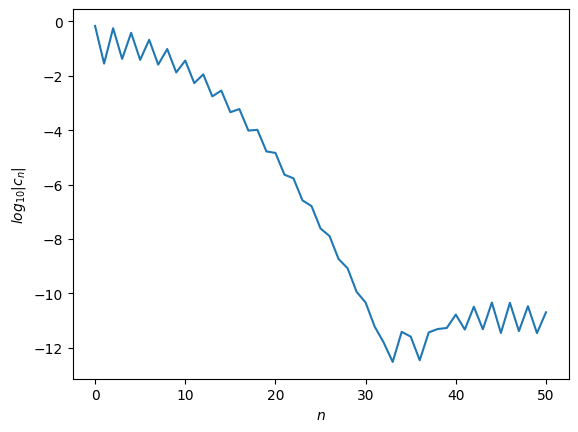

In [171]:
plt.plot(np.log10(np.abs(coeffs)))
plt.xlabel(r'$n$')
plt.ylabel(r'$log_{10}|c_n|$')
plt.show()

In [172]:
def calc_analytical(highest_coeff, t):
    #calculate on the x array defined before
    wavefunction = 0. #set to zero, will become array of len(x) in the loop
    for i in range(0, highest_coeff+1):
        Ei = (i+1)**2*np.pi**2*hbar**2/(2*m*L**2)
        wavefunction = wavefunction + coeffs[i]*np.exp(-1j*Ei*t/hbar)*np.sqrt(2/L)*np.sin((i + 1)*np.pi*x/L)
    
    return wavefunction
    

## Time Evolve Numerically

In [173]:
def create_crank_nicholson_operator():
    CN = np.zeros((len(x), len(x)), dtype = np.complex128)

    #first construct the tridiagonal part
    for i in range(0, len(x)):
        if i == 0:
            CN[0,0] = -2.
            CN[0,1] = 1.
        elif i == len(x)-1:
            CN[len(x)-1,len(x)-1] = -2.
            CN[len(x)-1, len(x)-2] = 1.
        else:
            CN[i,i] = -2.
            CN[i,i-1] = 1.
            CN[i,i+1] = 1.
    
    return (1j*hbar*dt)/(4*m*dx**2)*CN

CN = create_crank_nicholson_operator()

#get all the operators ready
A = np.identity(len(x),dtype=np.complex128) - CN
B = np.identity(len(x),dtype=np.complex128) + CN

C = np.linalg.inv(A)@B      

In [174]:
for i in range(1,len(t)): 
    psi[i,:] = C@psi[i-1,:]
    norm[i] = check_normalization(i)



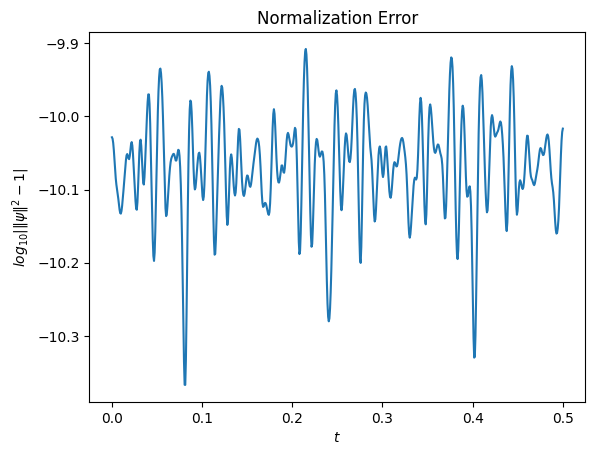

In [175]:
#check normalization

plt.plot(t, np.log10(np.abs(norm - 1)))
plt.xlabel(r'$t$')
plt.ylabel(r'$log_{10}|\|\psi\|^2 - 1|$')
plt.title('Normalization Error')
plt.show()

## Make Movie

In [183]:
def plot_wavefunction(index, ax):

    ax.plot(x, np.abs(psi[0,:])**2, label ='Initial Data', c='yellow')
    ax.plot(x, np.abs(psi[index,:])**2, label ='Numerical', c='red')
    

    #analytical sol
    analytical_sol = calc_analytical(50, t[index])
    ax.plot(x, np.abs(analytical_sol)**2, c='white', linestyle='dashed', label ='Analytical')

 
    ax.legend(loc=1)
    ax.set_ylim([-1,9])

    ax.set_xlabel(r'$x$', c='white', fontsize = 20)
    ax.set_ylabel(r'$\|\psi\|^2$', c='white', fontsize =20)
    ax.set_title('Gaussian Packet', c='white', fontsize = 20)
    ax.annotate( r'$t$ = '+str("%.3f" % t[index]), (0.05, 7), fontsize = 10, c='white')

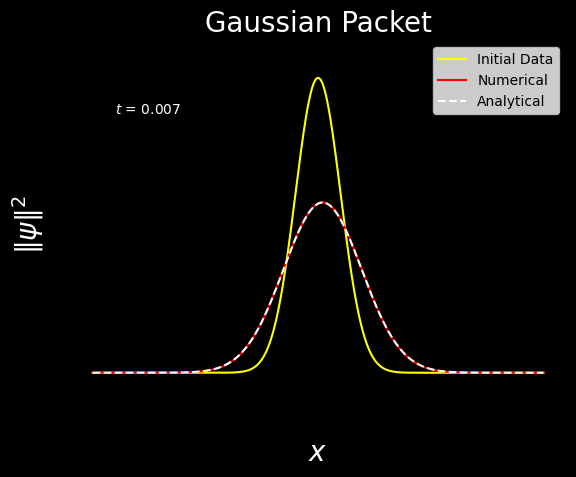

In [184]:

fig, ax = plt.subplots()
fig.patch.set_facecolor('black')
ax.set_facecolor('black')
plot_wavefunction(10, ax)
plt.show()

In [185]:
len(t)/3

236.0

In [72]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

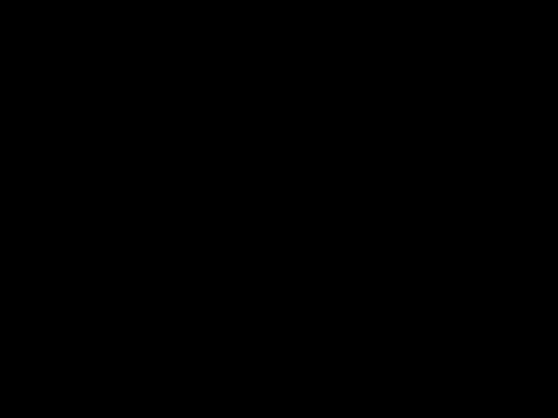

In [186]:
fig, ax = plt.subplots()
fig.patch.set_facecolor('black')
ax.set_facecolor('black')

with writer.saving(fig, 'time_dependent_gaussian.gif',100):
    for i in range(0, len(t)):
        if i%3==0:
            plot_wavefunction(i, ax)
            writer.grab_frame()
            ax.clear()